### Problem 1. Optimal Regressor for Mother-Daughter Height Data

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

**(a) - (b) Scatter plot segmented into 23 and 46 strips**

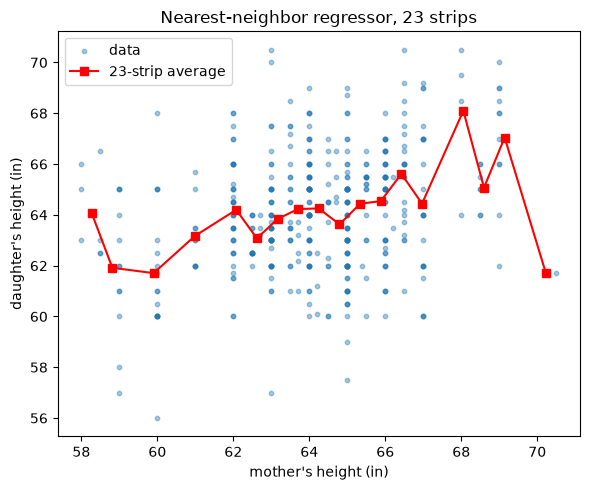

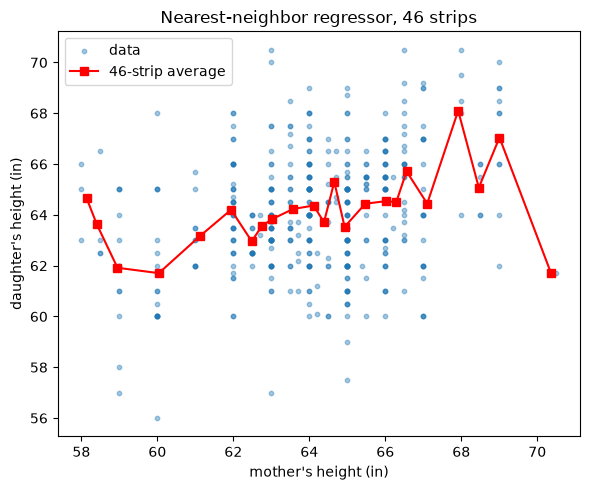

In [2]:
data = pd.read_csv("mother-daughter-height-pairs.csv")
mother, daughter = data.iloc[:,0].values, data.iloc[:,1].values

def strip_average(x, y, n_strips):
    edges = np.linspace(x.min(), x.max(), n_strips+1)
    centers, avgs = [], []
    for i in range(n_strips):
        if i < n_strips-1:
            mask = (x >= edges[i]) & (x < edges[i+1])
        else:
            mask = (x >= edges[i]) & (x <= edges[i+1])   # include right edge in last strip
        if mask.sum() > 0:
            centers.append(0.5*(edges[i]+edges[i+1]))
            avgs.append(y[mask].mean())
    return np.array(centers), np.array(avgs)

for n_strips in [23, 46]:
    centers, avgs = strip_average(mother, daughter, n_strips)
    plt.figure(figsize=(6,5))
    plt.scatter(mother, daughter, s=10, alpha=0.4, label="data")
    plt.plot(centers, avgs, 's-', color='red', label=f"{n_strips}-strip average")
    plt.xlabel("mother's height (in)"); plt.ylabel("daughter's height (in)")
    plt.title(f"Nearest-neighbor regressor, {n_strips} strips")
    plt.legend()
    plt.tight_layout()
    plt.show()

### Problem 2. Optimal Regressor given Probabilistic Data Model 

**(c) Overlay plots of $\hat{y}$ and $\hat{y}_{o,Lin}$ over $\{0 \leq x \leq 3, 0 \leq y \leq 4\}$**

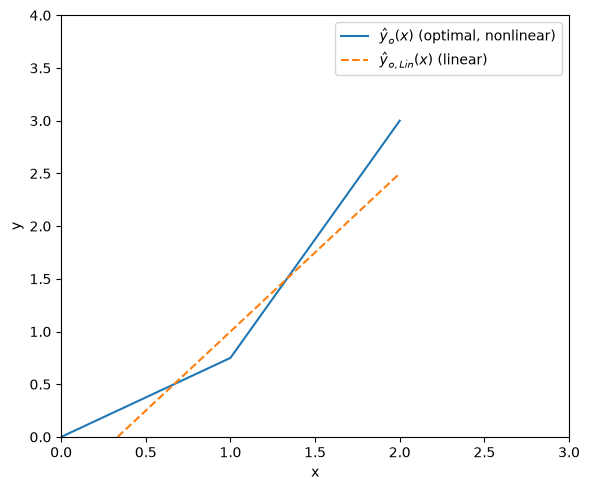

In [3]:
x1 = np.linspace(0, 1, 100)
x2 = np.linspace(1, 2, 100)
y_opt = np.concatenate([0.75*x1, 2.25*x2 - 1.5])
x_all = np.concatenate([x1, x2])
y_lin = 1.5*x_all - 0.5

plt.figure(figsize=(6,5))
plt.plot(x_all, y_opt, label=r"$\hat y_o(x)$ (optimal, nonlinear)")
plt.plot(x_all, y_lin, '--', label=r"$\hat y_{o,Lin}(x)$ (linear)")
plt.xlim(0,3); plt.ylim(0,4)
plt.xlabel("x"); plt.ylabel("y")
plt.legend(); plt.tight_layout()
plt.show()

### Problem 3. Optimal Regressor given Probabilistic Data Model

**(c) Overlay plots of $\hat{y}$ and $\hat{y}_{o,Lin}$**

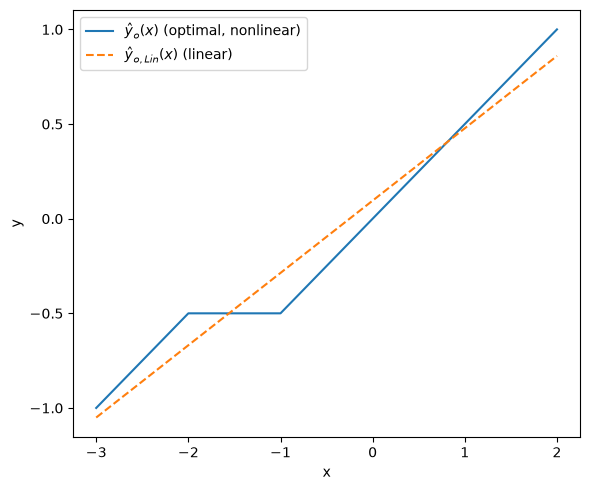

In [4]:
x1 = np.linspace(-3,-2,50); x2 = np.linspace(-2,-1,50); x3 = np.linspace(-1,2,100)
y_opt = np.concatenate([(x1+1)/2, -0.5*np.ones_like(x2), x3/2])
x_all = np.concatenate([x1,x2,x3])
y_lin = (34/89)*(x_all+0.25)

plt.figure(figsize=(6,5))
plt.plot(x_all, y_opt, label=r"$\hat y_o(x)$ (optimal, nonlinear)")
plt.plot(x_all, y_lin, '--', label=r"$\hat y_{o,Lin}(x)$ (linear)")
plt.xlabel("x"); plt.ylabel("y")
plt.legend(); plt.tight_layout()
plt.show()

### Problem 5. Regressors for Homosckedastic Model

**(c) Plots for optimum nonlinear regressor and linear regressors**

$M = 2, 3, 5; \sigma^2 = 0.1$

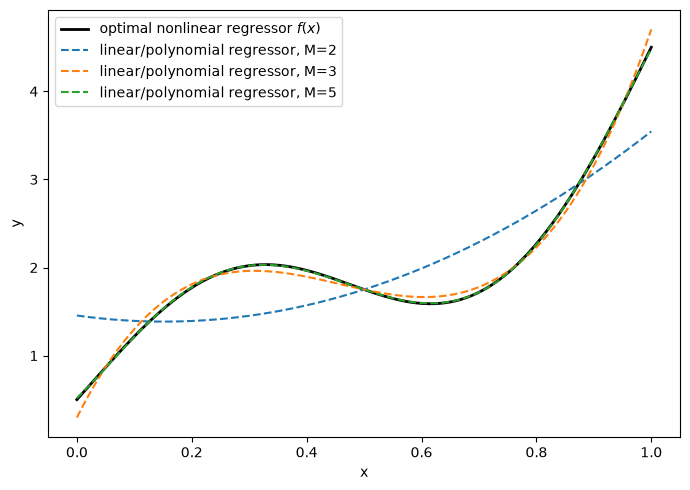

In [5]:
from scipy import integrate

M_values = [2, 3, 5]
sigma2 = 0.1

def f(x): return 0.5 + x + 3*x**2 + np.sin(2*np.pi*x)

def moments(M):
    mu_x = np.array([integrate.quad(lambda x: x**i, 0, 1)[0] for i in range(1, M+1)])
    Sigma_xx = np.array([[i*j/((i+1)*(j+1)*(i+j+1)) for j in range(1,M+1)] for i in range(1,M+1)])
    mu_y = integrate.quad(f, 0, 1)[0]
    sigma_xy = np.array([integrate.quad(lambda x: x**i * f(x), 0, 1)[0] - mu_x[i-1]*mu_y
                          for i in range(1, M+1)])
    return mu_x, Sigma_xx, mu_y, sigma_xy

x_grid = np.linspace(0, 1, 300)
plt.figure(figsize=(7,5))
plt.plot(x_grid, f(x_grid), 'k-', linewidth=2, label="optimal nonlinear regressor $f(x)$")

for M in M_values:
    mu_x, Sigma_xx, mu_y, sigma_xy = moments(M)
    w = np.linalg.solve(Sigma_xx, sigma_xy)         # w = Sigma_xx^{-1} sigma_xy
    w0 = mu_y - w @ mu_x
    X_grid = np.vstack([x_grid**i for i in range(1, M+1)]).T
    y_hat = w0 + X_grid @ w
    plt.plot(x_grid, y_hat, '--', label=f"linear/polynomial regressor, M={M}")

plt.xlabel("x"); plt.ylabel("y")
plt.legend(); plt.tight_layout()
plt.show()

### Problem 6. Gaussian Regression

**(a) MLE of the mean vector and covariance matrix**

In [6]:
data = pd.read_csv("mother-daughter-height-pairs.csv")
X = data.values   # columns: [mother height, daughter height]

m = X.mean(axis=0)
S = np.cov(X.T, bias=True)   # bias=True forces the 1/n MLE normalization, not 1/(n-1)
print("MLE mean m:", m)
print("MLE covariance S:\n", S)

MLE mean m: [64.15484581 64.10484581]
MLE covariance S:
 [[5.09053819 1.61682674]
 [1.61682674 5.52830251]]


**(b) Optimal Regressor and Population Loss**

In [7]:
slope = S[0,1]/S[0,0]
intercept = m[1] - slope*m[0]
Ro = S[1,1] - S[0,1]**2/S[0,0]
print(f"daughter_hat = {intercept:.4f} + {slope:.4f} * mother")
print("Ro:", Ro)

daughter_hat = 43.7284 + 0.3176 * mother
Ro: 5.014775529765705


**(c) Overlay of plots and optimal regressor**

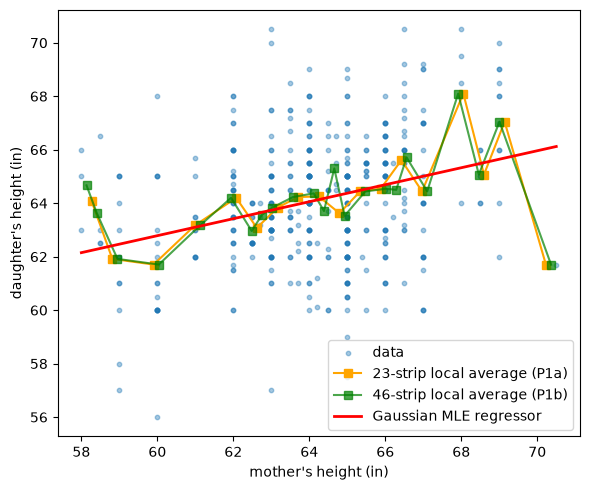

In [8]:
plt.figure(figsize=(6,5))
plt.scatter(mother, daughter, s=10, alpha=0.4, label="data")
c23, a23 = strip_average(mother, daughter, 23)
c46, a46 = strip_average(mother, daughter, 46)
plt.plot(c23, a23, 's-', color='orange', label="23-strip local average (P1a)")
plt.plot(c46, a46, 's-', color='green', alpha=0.7, label="46-strip local average (P1b)")

x_grid = np.linspace(mother.min(), mother.max(), 100)
plt.plot(x_grid, intercept + slope*x_grid, 'r-', linewidth=2, label="Gaussian MLE regressor")
plt.xlabel("mother's height (in)"); plt.ylabel("daughter's height (in)")
plt.legend(); plt.tight_layout()
plt.show()

### Problem 7. Binary Classification of Gaussian Input

**(a) Plots for the two densities**

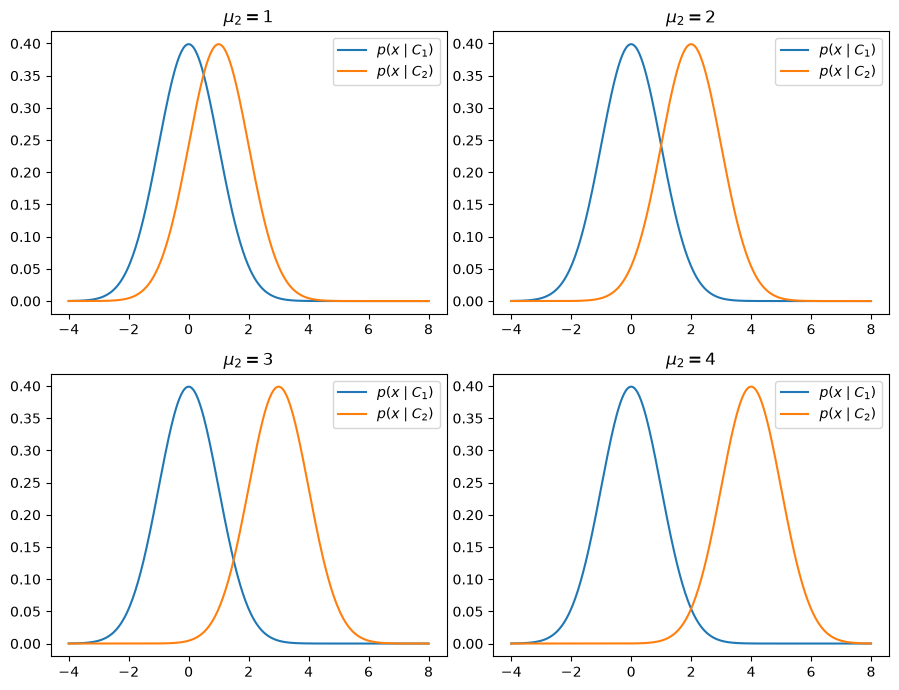

In [9]:
from scipy.stats import norm

fig, axes = plt.subplots(2, 2, figsize=(9,7))
x = np.linspace(-4, 8, 400)
for ax, mu2 in zip(axes.flat, [1,2,3,4]):
    ax.plot(x, norm.pdf(x, 0, 1), label="$p(x\\mid C_1)$")
    ax.plot(x, norm.pdf(x, mu2, 1), label="$p(x\\mid C_2)$")
    ax.set_title(f"$\\mu_2={mu2}$")
    ax.legend()
plt.tight_layout()
plt.show()

**(b) Pr(mistake)**

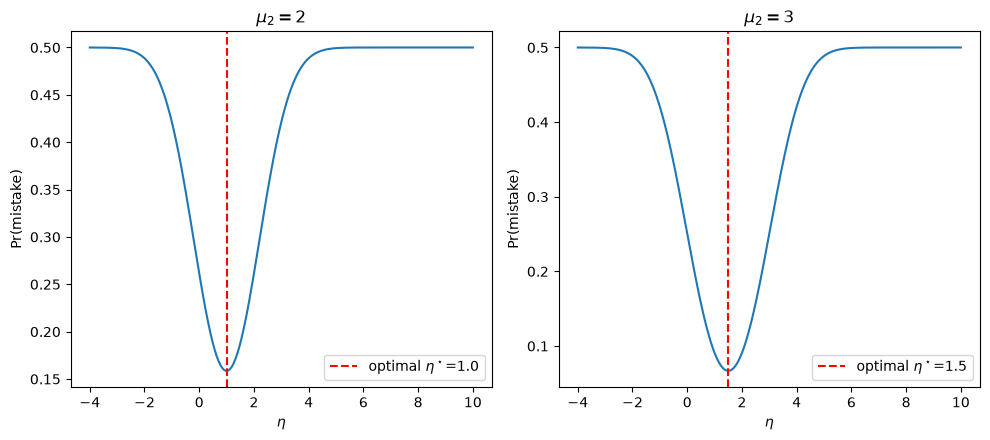

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10,4.5))
eta = np.linspace(-4, 10, 400)
for ax, mu2 in zip(axes, [2,3]):
    pr_mistake = 0.5*norm.cdf(eta-mu2) + 0.5*(1-norm.cdf(eta))
    ax.plot(eta, pr_mistake)
    ax.axvline(mu2/2, color='r', linestyle='--', label=f"optimal $\\eta^\\star$={mu2/2}")
    ax.set_title(f"$\\mu_2={mu2}$"); ax.set_xlabel("$\\eta$"); ax.set_ylabel("Pr(mistake)")
    ax.legend()
plt.tight_layout()
plt.show()

**(c) Final plots**

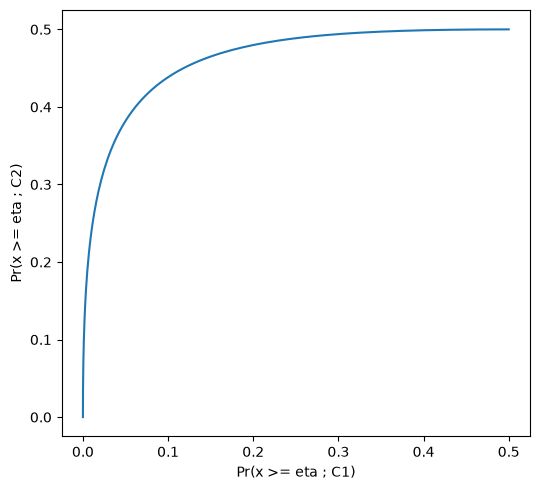

In [11]:
fig, ax = plt.subplots(figsize=(5.5,5))
mu2 = 2
Pr_C2 = 0.5*(1 - norm.cdf(eta - mu2))   # Pr(x >= eta ; C2)
Pr_C1 = 0.5*(1 - norm.cdf(eta))         # Pr(x >= eta ; C1)
ax.plot(Pr_C1, Pr_C2)
ax.set_xlabel("Pr(x >= eta ; C1)"); ax.set_ylabel("Pr(x >= eta ; C2)")
plt.tight_layout()
plt.savefig("p7c_roc.png", dpi=150)
plt.show()

### Problem 8. Binary Classification of Categorical Input

**(b) Decision boundary**

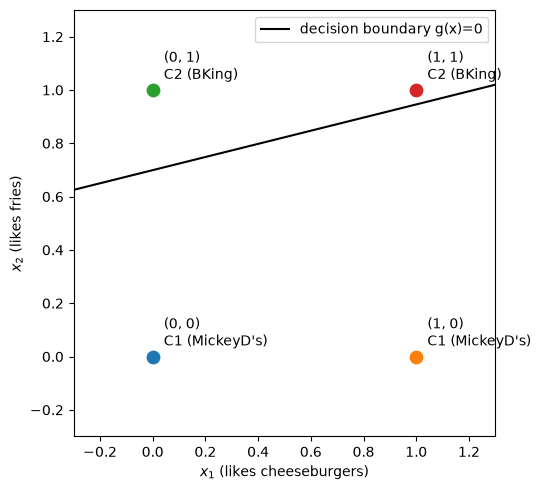

In [13]:

w1, w2, w0 = 0.4418, -1.7918, 1.2528

x1_line = np.linspace(-0.3, 1.3, 50)
x2_line = -(w1*x1_line + w0)/w2    # solving g(x)=0 for x2

plt.figure(figsize=(5.5,5))
plt.plot(x1_line, x2_line, 'k-', label="decision boundary g(x)=0")
for pt in [(0,0),(1,0),(0,1),(1,1)]:
    g = w1*pt[0]+w2*pt[1]+w0
    label = "C1 (MickeyD's)" if g>0 else "C2 (BKing)"
    plt.scatter(*pt, s=80, zorder=5)
    plt.annotate(f"{pt}\n{label}", pt, textcoords="offset points", xytext=(8,8))
plt.xlim(-0.3,1.3); plt.ylim(-0.3,1.3)
plt.xlabel("$x_1$ (likes cheeseburgers)"); plt.ylabel("$x_2$ (likes fries)")
plt.legend(); plt.tight_layout()
plt.show()